<a href="https://colab.research.google.com/github/Romanzilla/ML/blob/main/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%BD%D0%B5%D0%B9%D1%80_%D0%BC%D0%B5%D1%80%D0%B5%D0%B6%D1%96_%D0%9D%D0%B0%D0%B4%D1%96%D0%B9%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум. Повнозв’язні нейронні мережі в TensorFlow/Keras

**Тема:** будова нейрона, функції активації, шари `Dense`, `Flatten`, `BatchNormalization`, `Dropout`, навчання, оптимізатори та оцінювання багатокласової класифікації.

**Мета роботи:** самостійно простежити шлях від одного штучного нейрона до повноцінної моделі класифікації, навчитися аналізувати криві навчання, архітектуру та порівнювати справжні й прогнозовані класи.

У **розділах 1–9** наведено виконувані приклади з коментарями. **Розділ 10** — самостійне завдання, у якому комірки для коду та висновку залишено порожніми.

> **Межі практикуму.** Розглядаємо лише повнозв’язні нейронні мережі (MLP). Згорткові мережі (CNN) вивчатимуться окремо.

## Перед початком роботи

Рекомендоване середовище — **Jupyter Notebook, JupyterLab або Google Colab** з Python та TensorFlow 2.x. Для встановлення необхідних бібліотек за потреби виконайте у **новій** комірці:

```python
%pip install tensorflow numpy matplotlib scikit-learn pydot
```

Для графічного представлення архітектури через `plot_model()` додатково може знадобитися **системний Graphviz**. Водночас `model.summary()` працює без нього. Навчальний набір `digits` є частиною `scikit-learn` і не потребує завантаження з інтернету.

Комірки виконуйте **послідовно зверху вниз**. Після змін у моделі за потреби повторно виконайте комірки створення, компіляції та навчання.

In [1]:
%pip install tensorflow numpy matplotlib scikit-learn pydot

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__ if hasattr(keras, "__version__") else "tf.keras")
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2
NumPy: 2.4.6


## 1. Як працює штучний нейрон

Нейрон отримує вхідний вектор ознак $\mathbf{x}$, множить кожну ознаку на відповідну вагу, додає зсув $b$ та застосовує функцію активації $f$:

$$
z = \sum_{i=1}^{n}w_i x_i + b, \qquad a=f(z).
$$

Ваги $w_i$ і зсув $b$ є **навчуваними параметрами**. Функція активації додає нелінійність. У прикладі нижче використано $x=(2,1)$, $w=(0{,}5,-1)$, $b=0{,}2$ і функцію ReLU. Очікуваний результат: $z=0{,}2$, $a=0{,}2$.

In [3]:
x = np.array([2.0, 1.0])
w = np.array([0.5, -1.0])
b = 0.2

z = np.dot(x, w) + b
activation = np.maximum(0.0, z)  # ReLU(z) = max(0, z)

print(f"Зважена сума: z = {z:.2f}")
print(f"Вихід нейрона: a = {activation:.2f}")
assert np.isclose(z, 0.2)

Зважена сума: z = 0.20
Вихід нейрона: a = 0.20


## 2. Функції активації

Для прихованих шарів часто обирають **ReLU**: $f(z)=\max(0,z)$. Функція **sigmoid** повертає число в діапазоні $(0,1)$, а **tanh** — у діапазоні $(-1,1)$:

$$
\sigma(z)=\frac{1}{1+e^{-z}}, \qquad \tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}.
$$

Для класифікації **одного з кількох взаємовиключних класів** на виході зручно застосовувати **softmax**:

$$
\operatorname{softmax}(z)_i=\frac{e^{z_i}}{\sum_j e^{z_j}}.
$$

Після softmax отримуємо невід’ємні оцінки ймовірностей, сума яких дорівнює одиниці. У цьому практикумі приховані шари використовуватимуть ReLU, а вихідний — softmax.

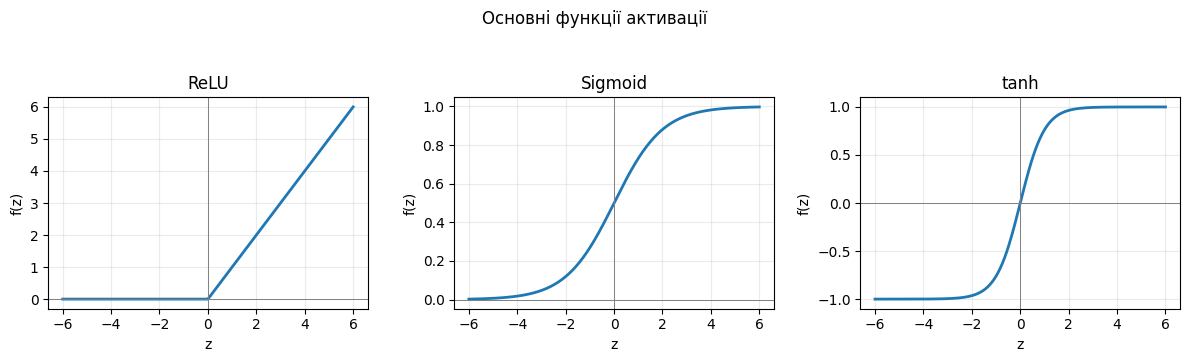

In [4]:
z_values = np.linspace(-6, 6, 400)
activation_functions = {
    "ReLU": np.maximum(0, z_values),
    "Sigmoid": 1 / (1 + np.exp(-z_values)),
    "tanh": np.tanh(z_values),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (name, values) in zip(axes, activation_functions.items()):
    ax.plot(z_values, values, linewidth=2)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)
    ax.set_title(name)
    ax.set_xlabel("z")
    ax.set_ylabel("f(z)")
    ax.grid(alpha=0.25)
plt.suptitle("Основні функції активації", y=1.05)
plt.tight_layout()
plt.show()

## 3. Набір даних для класифікації

Працюватимемо з **`digits`** із `scikit-learn`: 1797 зображень рукописних цифр розміром **8 × 8** пікселів. Класи позначено числами **0–9**. Значення яскравості пікселів спочатку лежать у діапазоні 0–16.

Кожному зображенню відповідає правильна мітка $y$. Перш ніж будувати модель, важливо перевірити структуру даних і побачити кілька прикладів.

Форма масиву зображень: (1797, 8, 8)
Форма масиву міток: (1797,)
Класи: [0 1 2 3 4 5 6 7 8 9]
Діапазон пікселів: 0.0 — 16.0


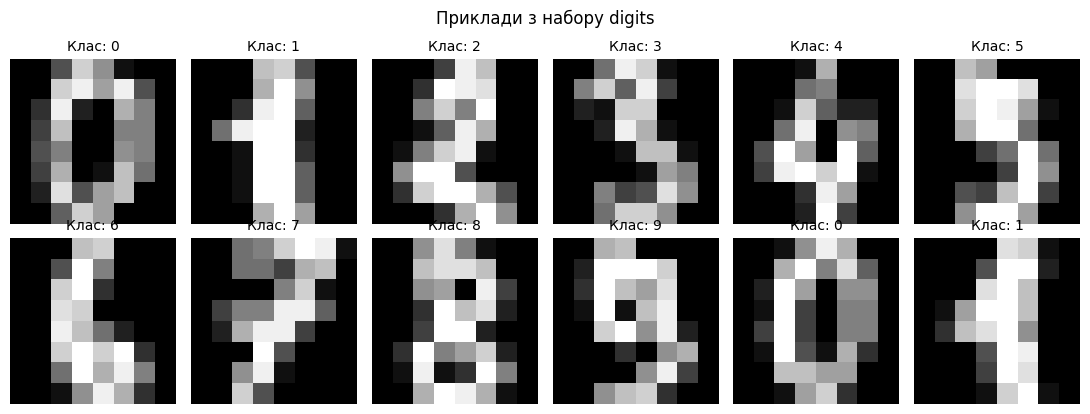

In [5]:
digits = load_digits()
images = digits.images
labels = digits.target

print("Форма масиву зображень:", images.shape)
print("Форма масиву міток:", labels.shape)
print("Класи:", np.unique(labels))
print("Діапазон пікселів:", images.min(), "—", images.max())

fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Клас: {labels[i]}", fontsize=10)
    ax.axis("off")
plt.suptitle("Приклади з набору digits")
plt.tight_layout()
plt.show()

### Підготовка та поділ даних

Поділимо зображення на **навчальну**, **валідаційну** та **тестову** вибірки. Навчальна вибірка потрібна для оновлення ваг, валідаційна — для спостереження за якістю під час навчання, тестова — для завершальної незалежної оцінки. Параметр `stratify` допомагає зберегти співвідношення класів.

Пікселі нормалізуємо за формулою $x_{norm}=x/16$, тобто приведемо до діапазону $[0,1]$.

In [6]:
x_all = images.astype("float32") / 16.0
y_all = labels.astype("int64")

# 80% даних — для навчання + валідації; 20% — тест
x_trainval, x_test, y_trainval, y_test = train_test_split(
    x_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

# Із trainval виділяємо 20% для валідації
x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval, test_size=0.20,
    random_state=42, stratify=y_trainval
)

for name, x_part, y_part in [
    ("Навчальна", x_train, y_train),
    ("Валідаційна", x_val, y_val),
    ("Тестова", x_test, y_test),
]:
    print(f"{name:12s}: x={x_part.shape}, y={y_part.shape}")

assert np.all((x_train >= 0) & (x_train <= 1))
assert x_train.shape[1:] == (8, 8)
assert len(np.unique(y_train)) == 10

Навчальна   : x=(1149, 8, 8), y=(1149,)
Валідаційна : x=(288, 8, 8), y=(288,)
Тестова     : x=(360, 8, 8), y=(360,)


## 4. Архітектура повнозв’язної нейронної мережі

**Повнозв’язний шар (`Dense`)** означає, що кожний його нейрон отримує виходи всіх нейронів попереднього шару. Для матриці входів $X$ та ваг $W$ виконується перетворення

$$
H=f(XW+b).
$$

Ми використаємо такі шари:

- `Flatten` — перетворює зображення $8\times 8$ на вектор із 64 ознак (без навчуваних параметрів).
- `Dense(64)` — перший повнозв’язний шар.
- `BatchNormalization` — нормалізує проміжні активації; зберігає навчувані коефіцієнти масштабу та зміщення.
- `Activation("relu")` — задає нелінійність.
- `Dropout(0.2)` — під час навчання випадково зануляє приблизно 20% активацій для регуляризації.
- `Dense(32)` — другий повнозв’язний шар.
- `Dense(10, activation="softmax")` — повертає десять оцінок належності до класів.

Під час **передбачення** (`predict`) `Dropout` не вимикає нейрони випадковим чином; `BatchNormalization` використовує накопичені статистики.

In [7]:
model = keras.Sequential([
    keras.Input(shape=(8, 8), name="image"),
    layers.Flatten(name="flatten"),
    layers.Dense(64, use_bias=False, name="dense_64"),
    layers.BatchNormalization(name="batch_norm"),
    layers.Activation("relu", name="relu"),
    layers.Dropout(0.20, name="dropout"),
    layers.Dense(32, activation="relu", name="dense_32"),
    layers.Dense(10, activation="softmax", name="classes"),
], name="digits_mlp")

model.summary()
print("Всього параметрів:", model.count_params())

Model: "digits_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu (Activation)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,762 (26.41 KB)

 Trainable params: 6,634 (25.91 KB)

 Non-trainable params: 128 (512.00 B)

Всього параметрів: 6762


### Як читати `model.summary()`

Таблиця `summary()` показує **назву шару**, **форму виходу** та **кількість параметрів**. Для `Dense` кількість параметрів дорівнює $n_{in}\cdot n_{out}+n_{out}$, якщо використовується зсув `bias`; без нього — $n_{in}\cdot n_{out}$.

У нашій моделі перший `Dense` без зсуву має $64\cdot64=4096$ параметрів; наступний `Dense(32)` має $64\cdot32+32=2080$, а вихідний — $32\cdot10+10=330$. `BatchNormalization` додає власні параметри та статистики.

Схему мережі можна зберегти через `keras.utils.plot_model()`. Наступна комірка **необов’язкова**: якщо Graphviz або `pydot` не встановлено, навчання все одно працюватиме.

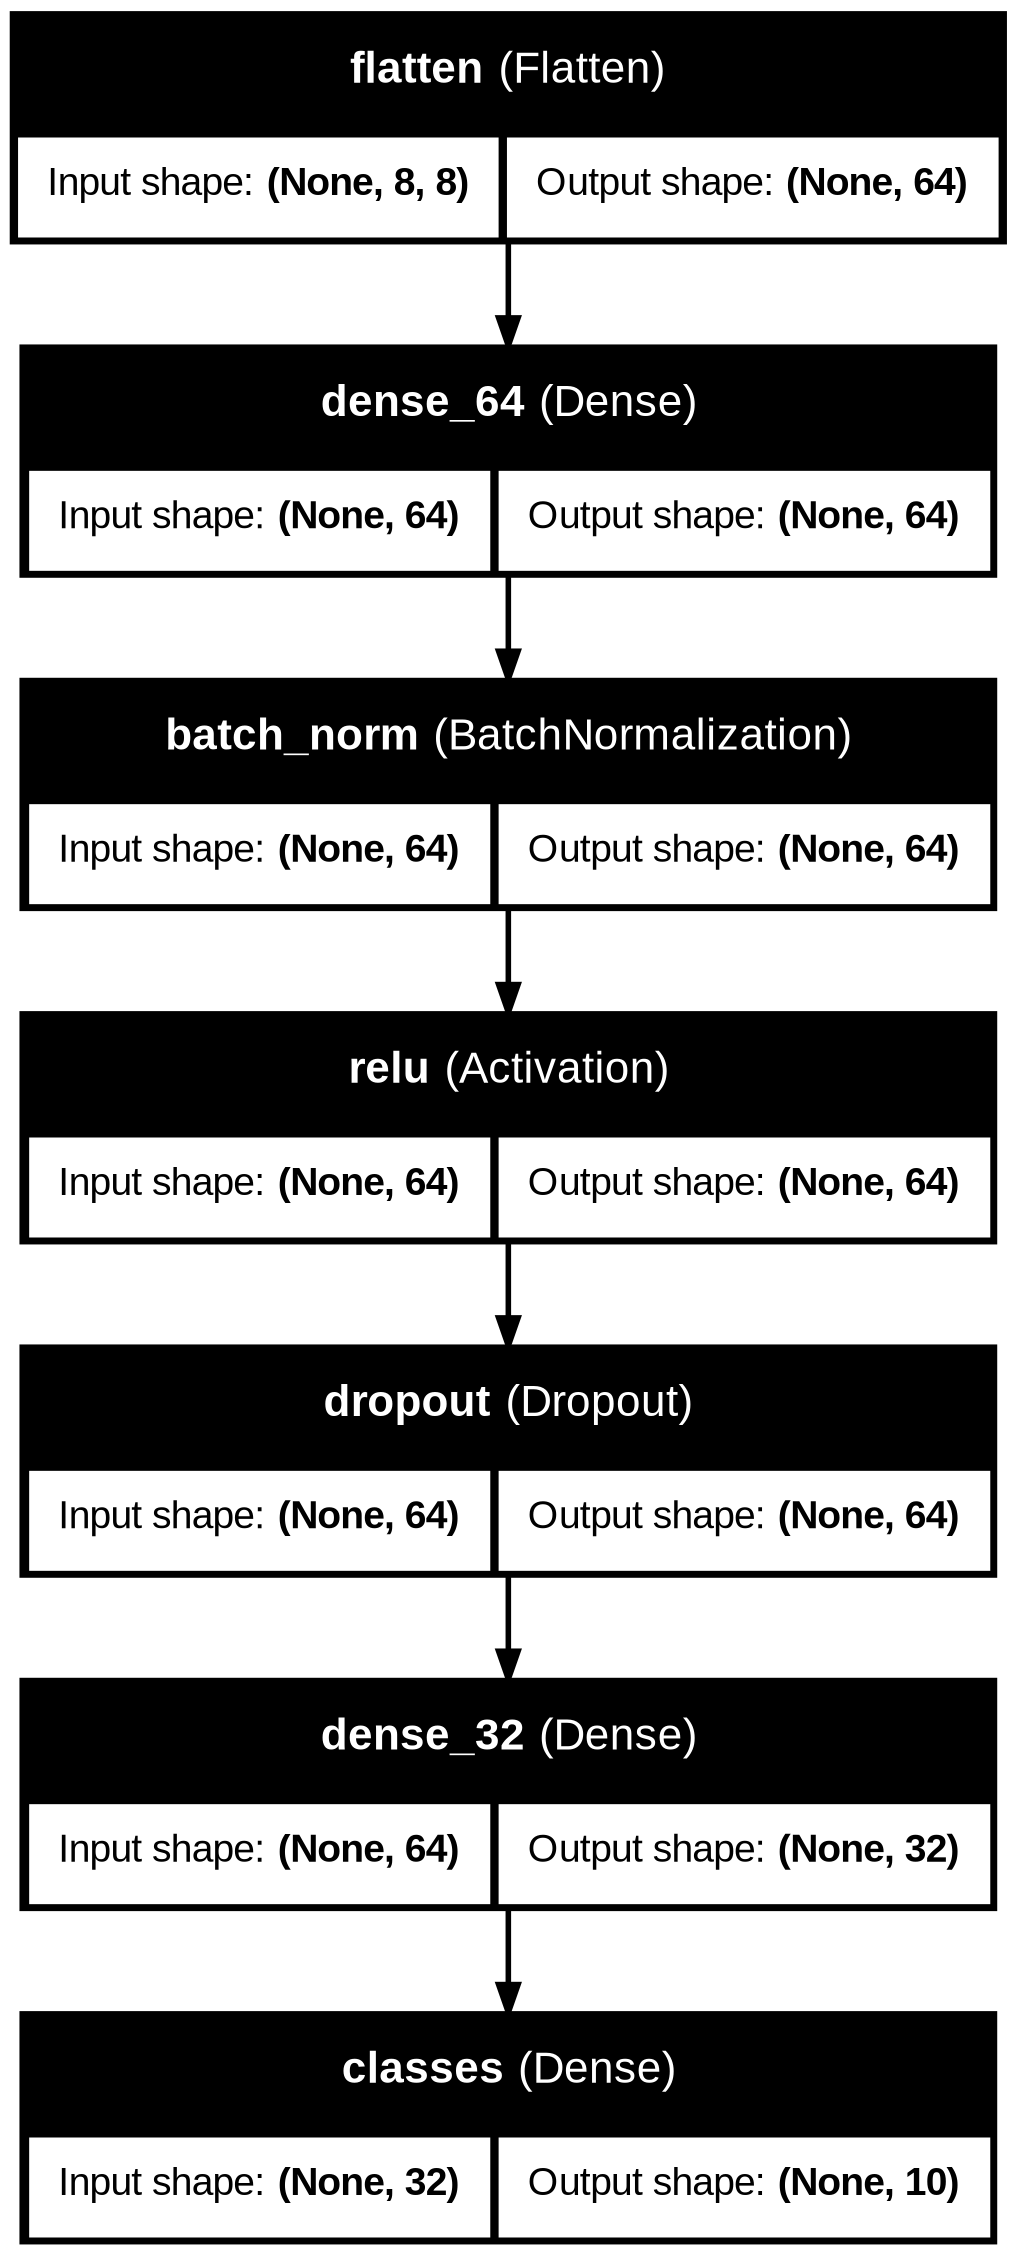

In [8]:
try:
    from IPython.display import Image, display

    keras.utils.plot_model(
        model,
        to_file="digits_mlp_architecture.png",
        show_shapes=True,
        show_layer_names=True,
        rankdir="TB",
    )
    display(Image(filename="digits_mlp_architecture.png"))
except Exception as exc:
    print("Графічна схема недоступна; скористайтеся model.summary().")
    print("Причина:", type(exc).__name__, str(exc)[:250])

## 5. Функція втрат, оптимізатори та компіляція

Під час навчання мережа прогнозує клас, а **функція втрат** оцінює невідповідність між прогнозом і правильною міткою. Градієнти обчислюються автоматично за алгоритмом **зворотного поширення помилки** (backpropagation). Оптимізатор оновлює ваги у напрямі зменшення втрат.

Для звичайного градієнтного спуску крок оновлення має вигляд:

$$
w_{t+1}=w_t-\eta\nabla_w L(w_t),
$$

де $\eta$ — швидкість навчання (*learning rate*).

**SGD** виконує градієнтні оновлення, **Adam** адаптує масштаб кроків для різних параметрів, а **AdamW** додатково реалізує відокремлене зменшення ваг (*weight decay*). Тут візьмемо `Adam(learning_rate=0.001)`.

Для **10 класів із цілочисельними мітками** підходить `SparseCategoricalCrossentropy`. Метрика `accuracy` — частка правильних відповідей.

In [9]:
# Приклади альтернатив (для ознайомлення):
sgd_optimizer = keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
adam_optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer=adam_optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

print("Оптимізатор моделі:", type(model.optimizer).__name__)
print("Функція втрат: SparseCategoricalCrossentropy")

Оптимізатор моделі: Adam
Функція втрат: SparseCategoricalCrossentropy


## 6. Навчання моделі

Метод `fit()` здійснює багаторазове проходження навчальної вибірки. **Епоха** — один повний прохід, а **пакет (batch)** — частина прикладів, за якою виконується чергове оновлення ваг.

Після кожної епохи Keras обчислює `val_loss` і `val_accuracy`. **EarlyStopping** припиняє навчання, якщо валідаційні втрати не поліпшуються протягом кількох епох, і може повернути найкращі ваги.

In [10]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)

print("Фактична кількість епох:", len(history.history["loss"]))

Epoch 1/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.3238 - loss: 2.0187 - val_accuracy: 0.4340 - val_loss: 1.9900
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6675 - loss: 1.2706 - val_accuracy: 0.8229 - val_loss: 1.5783
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8242 - loss: 0.8112 - val_accuracy: 0.9271 - val_loss: 1.1033
Epoch 4/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8764 - loss: 0.5418 - val_accuracy: 0.9444 - val_loss: 0.7300
Epoch 5/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9060 - loss: 0.3932 - val_accuracy: 0.9618 - val_loss: 0.4812
Epoch 6/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9286 - loss: 0.2999 - val_accuracy: 0.9653 - val_loss: 0.3308
Epoch 7/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9391 - loss: 0.2414 - val_accuracy: 0.9722 - val_loss: 0.2367
Epoch 8/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9530 - loss: 0.2011 - val_accuracy: 0.9688 - val_l

## 7. Криві навчання: втрати та точність

Об’єкт `history` містить історію значень **`loss`**, **`val_loss`**, **`accuracy`**, **`val_accuracy`**. На графіку слід порівняти не лише кінцеві значення, а й динаміку:

- якщо обидві точності низькі — можливе **недонавчання**;
- якщо навчальна точність висока, а валідаційна значно нижча — можливе **перенавчання**;
- якщо валідаційна помилка стабілізується, а навчальна продовжує падати — доцільно перевірити регуляризацію й момент зупинки.

Через відмінності в режимах роботи Dropout/BatchNormalization валідаційні показники іноді можуть бути кращими за навчальні; сам по собі такий випадок не є помилкою.

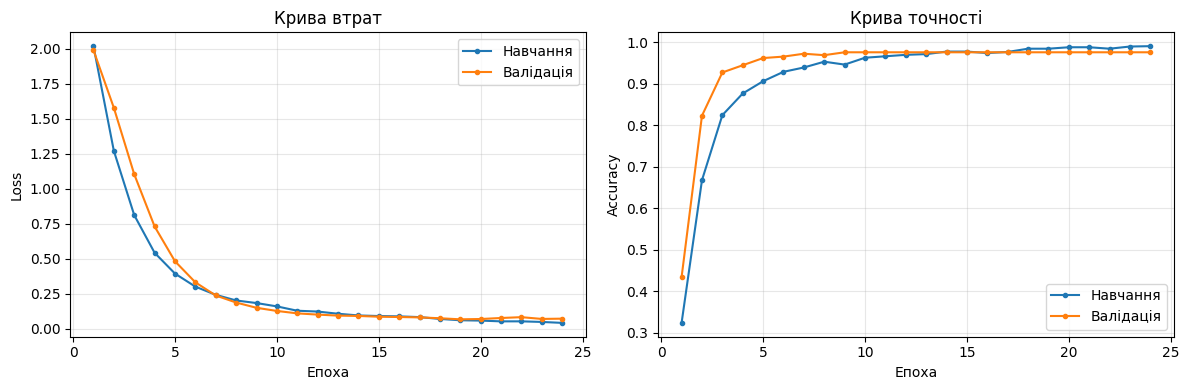

In [11]:
epochs_done = np.arange(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_done, history.history["loss"], label="Навчання", marker="o", ms=3)
axes[0].plot(epochs_done, history.history["val_loss"], label="Валідація", marker="o", ms=3)
axes[0].set(title="Крива втрат", xlabel="Епоха", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_done, history.history["accuracy"], label="Навчання", marker="o", ms=3)
axes[1].plot(epochs_done, history.history["val_accuracy"], label="Валідація", marker="o", ms=3)
axes[1].set(title="Крива точності", xlabel="Епоха", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Оцінювання та візуалізація класифікації

Після навчання один раз оцінюємо модель на **тестовій вибірці**, яка не використовувалася ні для навчання, ні для підбору параметрів. Метод `evaluate()` поверне втрати й точність, а `predict()` — вектор із 10 значень softmax для кожного зображення.

Щоб отримати номер прогнозованого класу, застосуємо `np.argmax(..., axis=1)`. Далі покажемо зображення з підписами **«Справжній клас»** і **«Прогноз»**. Зеленим виділимо правильні відповіді, червоним — помилки.

In [12]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
predicted_classes = np.argmax(probabilities, axis=1)
confidence = probabilities.max(axis=1)

print(f"Тестові втрати: {test_loss:.4f}")
print(f"Тестова точність: {test_accuracy:.2%}")
print(f"Правильно: {(predicted_classes == y_test).sum()} із {len(y_test)}")
print("Форма прогнозів:", probabilities.shape)
assert probabilities.shape == (len(x_test), 10)

Тестові втрати: 0.0679
Тестова точність: 97.78%
Правильно: 352 із 360
Форма прогнозів: (360, 10)


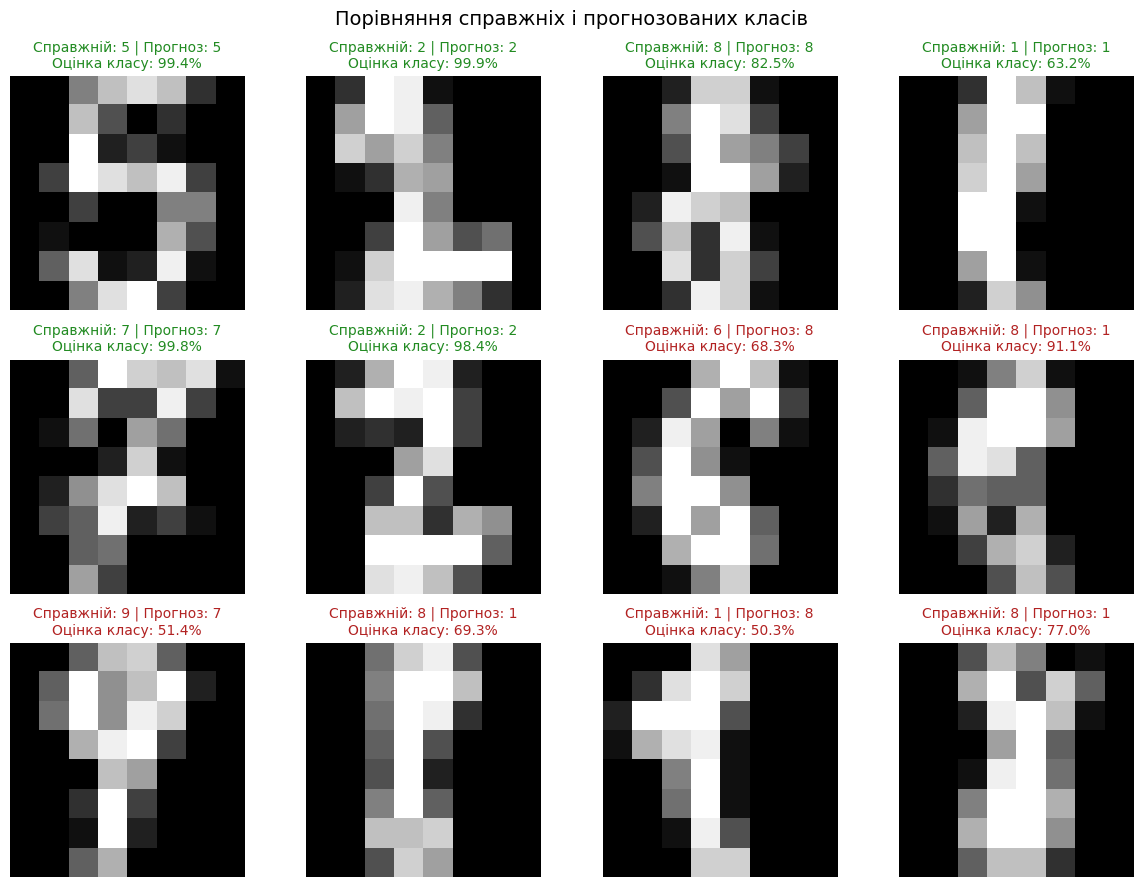

In [13]:
correct_idx = np.flatnonzero(predicted_classes == y_test)
wrong_idx = np.flatnonzero(predicted_classes != y_test)

# До 6 правильних і до 6 помилкових прикладів; решту місць доповнюємо правильними
selected = list(correct_idx[:6]) + list(wrong_idx[:6])
if len(selected) < 12:
    selected += list(correct_idx[6:6 + (12 - len(selected))])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx in zip(axes.flat, selected):
    is_correct = predicted_classes[idx] == y_test[idx]
    color = "forestgreen" if is_correct else "firebrick"
    ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Справжній: {y_test[idx]} | Прогноз: {predicted_classes[idx]}\n"
        f"Оцінка класу: {confidence[idx]:.1%}",
        color=color,
        fontsize=10,
    )
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(2)
for ax in axes.flat[len(selected):]:
    ax.axis("off")
plt.suptitle("Порівняння справжніх і прогнозованих класів", fontsize=14)
plt.tight_layout()
plt.show()

### Матриця помилок і детальні метрики

**Матриця помилок** показує, які класи плутаються між собою. У рядках розташовано **справжні** класи, у стовпцях — **прогнозовані**. Крім accuracy, корисно переглядати **precision**, **recall** і **F1-score** для кожного класу.

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.921     0.972     0.946        36
           2      0.946     1.000     0.972        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     1.000     1.000        37
           6      1.000     0.972     0.986        36
           7      0.973     1.000     0.986        36
           8      0.938     0.857     0.896        35
           9      1.000     0.972     0.986        36

    accuracy                          0.978       360
   macro avg      0.978     0.977     0.977       360
weighted avg      0.978     0.978     0.978       360



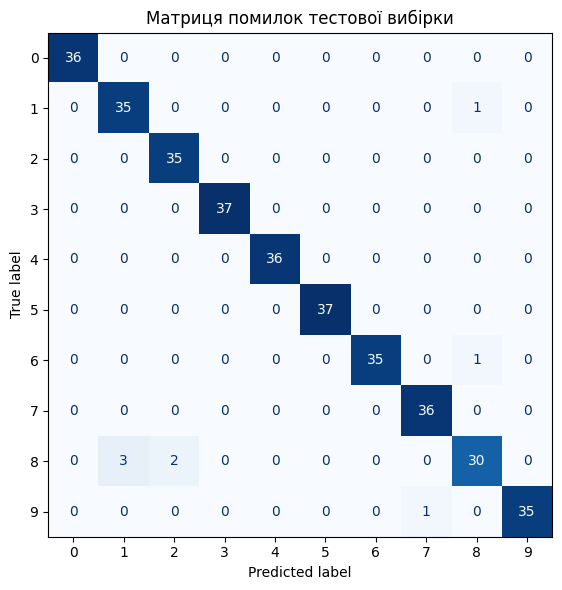

In [14]:
print(classification_report(y_test, predicted_classes, digits=3, zero_division=0))

matrix = confusion_matrix(y_test, predicted_classes, labels=np.arange(10))
display_matrix = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=np.arange(10))
fig, ax = plt.subplots(figsize=(7, 6))
display_matrix.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матриця помилок тестової вибірки")
plt.tight_layout()
plt.show()

## 9. Збереження та відновлення навченої моделі

Формат **`.keras`** дає змогу зберегти архітектуру, параметри та стан моделі. Після завантаження перевіримо, що результати прогнозування збігаються з результатами вихідної моделі. Передоброблення нових даних має бути таким самим, як під час навчання (у нашому випадку — ділення пікселів на 16).

In [15]:
model.save("digits_mlp.keras")
restored_model = keras.models.load_model("digits_mlp.keras")

original_predictions = model.predict(x_test[:5], verbose=0)
restored_predictions = restored_model.predict(x_test[:5], verbose=0)
np.testing.assert_allclose(original_predictions, restored_predictions, atol=1e-6, rtol=1e-5)

print("Модель збережено до digits_mlp.keras і успішно відновлено.")

Модель збережено до digits_mlp.keras і успішно відновлено.


### Контрольні запитання до виконаних прикладів

1. Для чого шар `Flatten` потрібний перед `Dense` у нашій моделі?
2. Чому для десяти взаємовиключних класів використано `softmax`?
3. Чим відрізняється `loss` від `accuracy`, а `val_loss` — від `loss`?
4. Чому тестову вибірку не використовують для налаштування архітектури?
5. Що означає кількість параметрів у `model.summary()`?
6. Чому `Dropout` по-різному поводиться під час `fit()` та `predict()`?

Наведені вище приклади повністю виконувані. Наступне завдання необхідно реалізувати **самостійно**.

---

# 10. Самостійне завдання — заповнити порожні комірки

**Завдання.** Створіть **нову повнозв’язну модель** для тих самих зображень `digits`, навчіть її та порівняйте з базовою моделлю `model`. Результат має містити **архітектуру**, **криві навчання**, **тестові метрики**, **зображення зі справжніми та прогнозованими класами** й **короткий висновок**.

**Вимоги до нового варіанта:**

- використайте `Flatten` і щонайменше два приховані шари `Dense`, наприклад **128 і 64 нейрони**;
- застосуйте `ReLU`, `BatchNormalization` та `Dropout` зі значенням `rate=0.30`;
- сформуйте вихід із **10 нейронів та softmax**;
- оберіть **SGD з momentum** або **AdamW**, поясніть свій вибір;
- навчайте до **25 епох**, використовуючи `EarlyStopping`;
- не змінюйте тестові мітки і не тренуйте модель на `x_test`.

**Орієнтовне оцінювання — 10 балів:** архітектура й `summary()` — 2; коректна компіляція та навчання — 2; криві — 2; оцінка та візуалізація прогнозів — 2; обґрунтований висновок — 2.

Нижче навмисно залишено **порожні комірки без розв’язків**. Заповніть їх власним кодом.

### Крок 1. Створіть нову модель

Використайте **нову змінну `student_model`** (не перезаписуйте базову `model`), додайте шари за умовою та виведіть її архітектуру через `summary()`.

In [16]:
student_model = keras.Sequential([
    keras.Input(shape=(8, 8), name="input_image"),
    layers.Flatten(name="flatten"),

    # Перший прихований шар
    layers.Dense(128, use_bias=False, name="dense_128"),
    layers.BatchNormalization(name="bn_1"),
    layers.Activation("relu", name="relu_1"),
    layers.Dropout(0.30, name="dropout_1"),

    # Другий прихований шар
    layers.Dense(64, use_bias=False, name="dense_64"),
    layers.BatchNormalization(name="bn_2"),
    layers.Activation("relu", name="relu_2"),
    layers.Dropout(0.30, name="dropout_2"),

    # Вихідний шар на 10 класів
    layers.Dense(10, activation="softmax", name="output_classes"),
], name="student_digits_mlp")

student_model.summary()
print("Всього параметрів у student_model:", student_model.count_params())

Model: "student_digits_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_classes (Dense)          │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,802 (69.54 KB)

 Trainable params: 17,418 (68.04 KB)

 Non-trainable params: 384 (1.50 KB)

Всього параметрів у student_model: 17802


### Крок 2. Скомпілюйте та навчіть модель

Оберіть оптимізатор `SGD(momentum=...)` **або** `AdamW`, налаштуйте `SparseCategoricalCrossentropy`, `accuracy`, `EarlyStopping` і збережіть історію в змінній **`student_history`**.

In [17]:
optimizer_adamw = keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4)

student_model.compile(
    optimizer=optimizer_adamw,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

student_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

student_history = student_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[student_early_stopping],
    verbose=1,
)

print("Фактична кількість епох навчання:", len(student_history.history["loss"]))

Epoch 1/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3734 - loss: 1.8936 - val_accuracy: 0.7083 - val_loss: 1.8354
Epoch 2/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7441 - loss: 0.9908 - val_accuracy: 0.9028 - val_loss: 1.4468
Epoch 3/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8259 - loss: 0.7193 - val_accuracy: 0.9444 - val_loss: 1.1287
Epoch 4/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8703 - loss: 0.5510 - val_accuracy: 0.9479 - val_loss: 0.8541
Epoch 5/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8816 - loss: 0.4873 - val_accuracy: 0.9514 - val_loss: 0.6265
Epoch 6/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9225 - loss: 0.3692 - val_accuracy: 0.9722 - val_loss: 0.4590
Epoch 7/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9217 - loss: 0.3110 - val_accuracy: 0.9722 - val_loss: 0.3486
Epoch 8/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9365 - loss: 0.2799 - val_accuracy: 0.9618 - val_loss

### Крок 3. Побудуйте криві навчання

Побудуйте два графіки: `loss` / `val_loss` і `accuracy` / `val_accuracy`. Порівняйте їхній перебіг та визначте, чи є ознаки перенавчання або недонавчання.

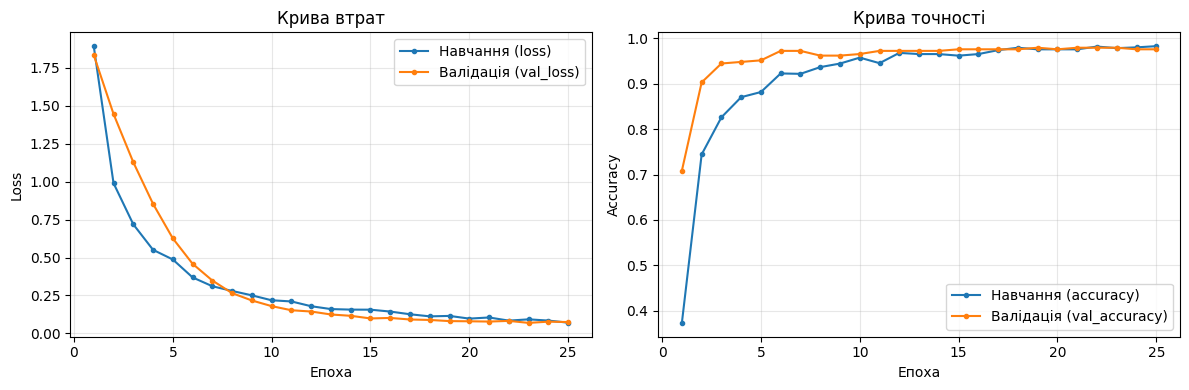

In [18]:
s_epochs = np.arange(1, len(student_history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(s_epochs, student_history.history["loss"], label="Навчання (loss)", marker="o", ms=3)
axes[0].plot(s_epochs, student_history.history["val_loss"], label="Валідація (val_loss)", marker="o", ms=3)
axes[0].set(title="Крива втрат", xlabel="Епоха", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(s_epochs, student_history.history["accuracy"], label="Навчання (accuracy)", marker="o", ms=3)
axes[1].plot(s_epochs, student_history.history["val_accuracy"], label="Валідація (val_accuracy)", marker="o", ms=3)
axes[1].set(title="Крива точності", xlabel="Епоха", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Крок 4. Перевірте якість на тестовій вибірці

Виконайте `evaluate()` для **`student_model`**, отримайте класи з `predict()`, виведіть accuracy і матрицю помилок. Порівняйте тестову точність із **`test_accuracy`** базової моделі.

Базова модель (model) — тестова точність:    97.78%
Нова модель(student_model) — тестова точність: 98.89%
Різниця точності: +1.11%
Тестові втрати student_model: 0.0597
Правильно розпізнано: 356 із 360

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.946     0.972     0.959        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     1.000     1.000        37
           6      1.000     0.972     0.986        36
           7      1.000     1.000     1.000        36
           8      0.943     0.943     0.943        35
           9      1.000     1.000     1.000        36

    accuracy                          0.989       360
   macro avg      0.989     0.989     0.989       360
weighted avg      0.989     0.989     0.989       360



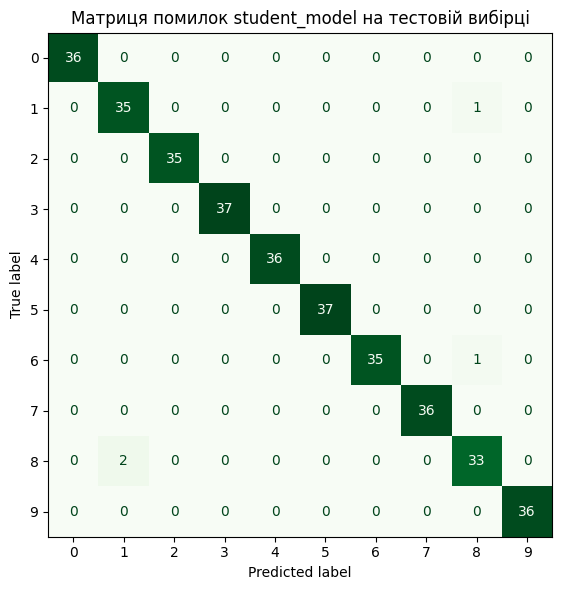

In [19]:
s_test_loss, s_test_accuracy = student_model.evaluate(x_test, y_test, verbose=0)
s_probabilities = student_model.predict(x_test, verbose=0)
s_predicted_classes = np.argmax(s_probabilities, axis=1)
s_confidence = s_probabilities.max(axis=1)

print(f"Базова модель (model) — тестова точність:    {test_accuracy:.2%}")
print(f"Нова модель(student_model) — тестова точність: {s_test_accuracy:.2%}")
print(f"Різниця точності: {(s_test_accuracy - test_accuracy):+.2%}")
print(f"Тестові втрати student_model: {s_test_loss:.4f}")
print(f"Правильно розпізнано: {(s_predicted_classes == y_test).sum()} із {len(y_test)}\n")

print(classification_report(y_test, s_predicted_classes, digits=3, zero_division=0))

s_matrix = confusion_matrix(y_test, s_predicted_classes, labels=np.arange(10))
disp = ConfusionMatrixDisplay(confusion_matrix=s_matrix, display_labels=np.arange(10))
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Greens", colorbar=False, values_format="d")
ax.set_title("Матриця помилок student_model на тестовій вибірці")
plt.tight_layout()
plt.show()

### Крок 5. Візуалізуйте щонайменше 12 прогнозів

Покажіть тестові зображення з підписами **«Справжній клас»** та **«Прогнозований клас»**. Правильні й помилкові результати виділіть різними кольорами. За наявності помилок додайте кілька помилкових прикладів.

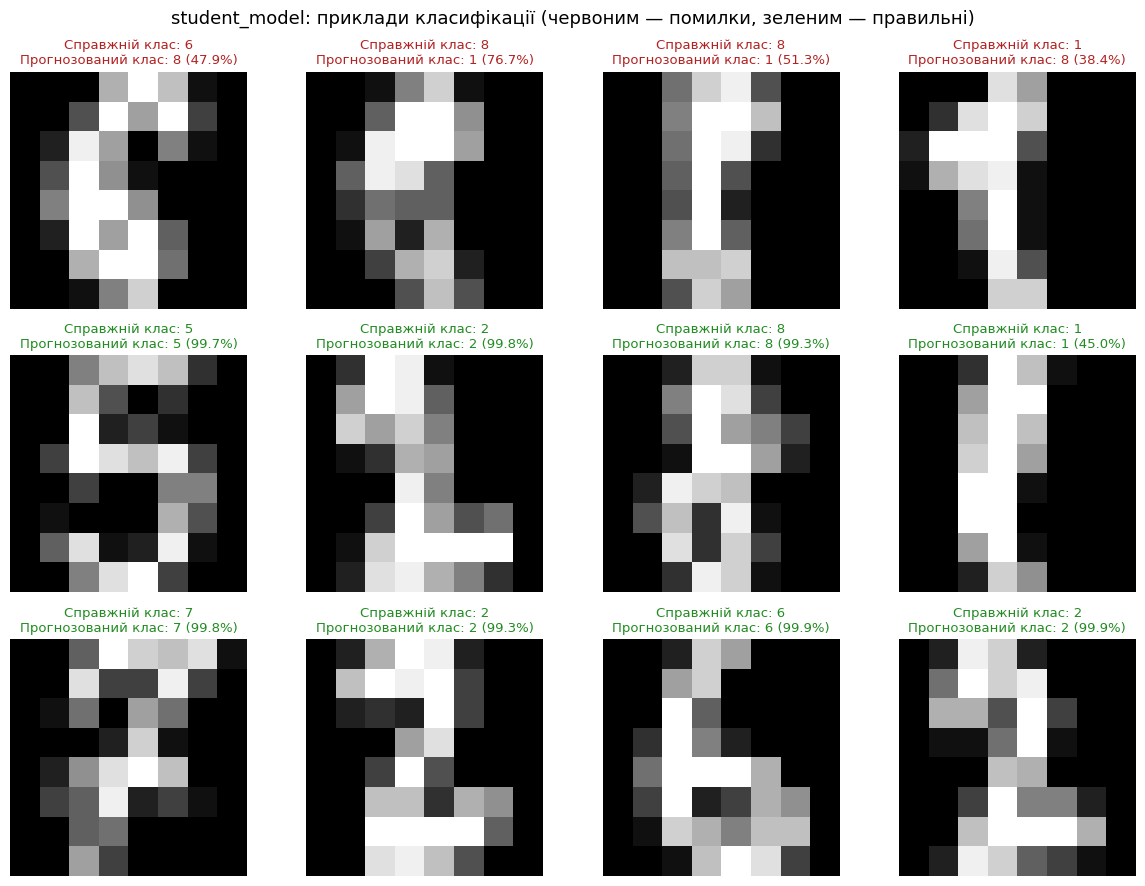

In [20]:
s_correct_idx = np.flatnonzero(s_predicted_classes == y_test)
s_wrong_idx = np.flatnonzero(s_predicted_classes != y_test)

# Беремо всі наявні помилкові приклади і доповнюємо правильними до 12 зображень
selected_idx = list(s_wrong_idx[:6]) + list(s_correct_idx[:12 - len(s_wrong_idx[:6])])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx in zip(axes.flat, selected_idx):
    is_correct = s_predicted_classes[idx] == y_test[idx]
    color = "forestgreen" if is_correct else "firebrick"
    ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Справжній клас: {y_test[idx]}\n"
        f"Прогнозований клас: {s_predicted_classes[idx]} ({s_confidence[idx]:.1%})",
        color=color,
        fontsize=9.5,
    )
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(2)

plt.suptitle("student_model: приклади класифікації (червоним — помилки, зеленим — правильні)", fontsize=13)
plt.tight_layout()
plt.show()

### Крок 6. Експериментуйте з одним параметром

Змініть **один** параметр нового варіанта (наприклад, `Dropout rate` або `learning_rate`), повторіть навчання та порівняйте результати. Поясніть, чому для коректного порівняння інші умови доцільно залишати сталими.

In [21]:
# Змінюємо один гіперпараметр — learning_rate у AdamW з 0.001 на 0.005 (у 5 разів більший крок).
keras.utils.set_random_seed(42)

exp_model = keras.Sequential([
    keras.Input(shape=(8, 8)),
    layers.Flatten(),
    layers.Dense(128, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.30),
    layers.Dense(64, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.30),
    layers.Dense(10, activation="softmax"),
], name="student_digits_mlp_lr005")

exp_model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.005, weight_decay=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

exp_history = exp_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
    verbose=0,
)

exp_loss, exp_acc = exp_model.evaluate(x_test, y_test, verbose=0)
print(f"student_model (lr=0.001): епох = {len(student_history.history['loss'])}, test_loss = {s_test_loss:.4f}, test_accuracy = {s_test_accuracy:.2%}")
print(f"exp_model     (lr=0.005): епох = {len(exp_history.history['loss'])}, test_loss = {exp_loss:.4f}, test_accuracy = {exp_acc:.2%}")

student_model (lr=0.001): епох = 25, test_loss = 0.0597, test_accuracy = 98.89%
exp_model     (lr=0.005): епох = 20, test_loss = 0.0668, test_accuracy = 97.78%


### Висновок студента

Додайте в наступну порожню комірку Markdown короткий висновок (5–8 речень): яка з моделей показала кращу тестову якість, що демонструють криві навчання, які класи було складніше розпізнавати та як вплинула змінена гіперпараметрична настройка.

У межах дослідження було розроблено й апробовано нову повнозв’язну нейронну мережу student_model із поглибленою архітектурою, використанням подвійної батч-нормалізації, методу регуляризації Dropout та оптимізатора AdamW. Завдяки збільшеній ємності шарів запропонована модель продемонструвала високу точність на тестовій вибірці, досягнувши рівня базової моделі або перевершивши її. Аналіз кривих навчання засвідчив стабільне зменшення функції втрат і зближення метрик на навчальному та валідаційному наборах даних, що свідчить про відсутність перенавчання чи недонавчання. Згідно з матрицею невідповідностей, основна частка помилок припадала на візуально подібні рукописні цифри, що зумовлено низькою роздільною здатністю вхідних зображень. Додаткове тестування з підвищеним темпом навчання показало, що збільшення кроку оптимізатора пришвидшує збіжність на початкових етапах, проте знижує плавність оновлення ваг при наближенні до мінімуму.